# 2. Comparing global and periodic STM grey boxes

The six states are position and velocity departure from the nominal NRHO. In corridor-scaled coordinates,

$$e_{k+1}=A_k e_k+B_k\operatorname{diag}(g(\phi_k))u_k+w_k,\qquad z_{j,k}=h_j(t_k,x_{\rm nom}(t_k))+C_{j,k}e_k+v_{j,k},$$
$$\dot\Phi=F(t)\Phi,\quad A_k=J^{-1}\Phi(t_{k+1},t_k)J,\quad C_{j,k}=\left.\frac{\partial h_j}{\partial x}\right|_{x_{\rm nom}(t_k)}J.$$

$z_{j,k}$ contains the two angles from visible LSO $j$, so **$C_{j,k}$ is not the identity**. The measurement noise enters additively after the ideal angle map: $v_{j,k}\sim\mathcal{N}(0,R)$ with $R=\sigma_\theta^2 I_2$ and $\sigma_\theta=1$ arcsec in the synthetic sensor generator. Draws are independent across angle components, sites and epochs, which is a white-noise assumption. No real sensor calibration data are used to justify white or Gaussian noise, and bias or colored noise are not modeled. The innovation tests check this assumption against the synthetic data. Known physics fixes the repeatable $A_k$ and $B_k$ along the nominal orbit. The global baseline fits one set of three mean gains. The periodic fit replaces $g$ with $g(\phi_k)$, an interpolation of overlapping phase windows. The last window blends into the first. The simulator uses constant physical gains, so any fitted phase variation represents effective model correction rather than changing actuator hardware.

In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display, Markdown
from halo_tracking import stationkeeping as physics
from halo_tracking import lso_stationkeeping as sk
from halo_tracking import stationkeeping_diagnostics as sd
from halo_tracking import lso_diagnostics as ld
from halo_tracking import lso_report_plots as plots
ROOT=Path.cwd()
if not (ROOT/'configs').exists(): ROOT=ROOT.parent
OUT=ROOT/'artifacts'/'stationkeeping'
OUT.mkdir(parents=True,exist_ok=True)
plots.style()
def table(headers,rows):
    display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
                     '\n'.join('| '+' | '.join(map(str,row))+' |' for row in rows)))

orbit,data=sk.restore_study(ROOT,OUT/'data')
global_fit=sk.fit_greybox(orbit,data['training'])
fit=sk.fit_periodic_greybox(orbit,data['training'],
    windows=orbit.settings['periodic_gain_windows'],
    smoothing=orbit.settings['periodic_gain_smoothing'])
gains=fit['gains']
models={'Global gains':global_fit['gains'],'Periodic gains':gains}
table(['Phase [deg]','X gain','Y gain','Z gain'],
      [(f'{phase:.0f}',*(f'{value:.4f}' for value in local))
       for phase,local in zip(fit['knot_phase_deg'],fit['knot_gains'])])
print('Global gains:',global_fit['gains'])

def save_fit(name, result):
    values={k:v.tolist() if isinstance(v,np.ndarray) else v for k,v in result.items()}
    (OUT/name).write_text(json.dumps(values,indent=2)+'\n')

save_fit('greybox_fit.json',fit)
save_fit('global_greybox_fit.json',global_fit)

Global gains: [0.99307395 1.04595337 0.96442523]


| Phase [deg] | X gain | Y gain | Z gain |
| --- | --- | --- | --- |
| 0 | 0.9550 | 1.0575 | 1.0780 |
| 60 | 1.0082 | 1.0341 | 1.0857 |
| 120 | 1.0008 | 1.0853 | 1.0558 |
| 180 | 0.9909 | 1.0790 | 0.8998 |
| 240 | 0.9924 | 1.0018 | 0.9914 |
| 300 | 0.9498 | 1.0346 | 1.0533 |

## Identification and held-out validation

Following Studios 5 and 11, minimize covariance-standardized **raw angular innovations** on training trajectories, updating only when an LSO is visible. No generated full-state observations or saved truth enter the fit. Filtered state histories are correlated outputs, so they support exploratory plots and guidance, not independent-measurement regression.

Both variants use the same training, validation and test trajectories. Lecture 13 motivates a local approximation when full-record stationarity is doubtful. Here windows are indexed by orbital phase, so training can pool repeated passages through the same phase. Adjacent gains are regularized towards one another, with no test-driven choice of window count. Independent test trajectories assess angular prediction and navigation accuracy. Free propagation uses its initial angular update and then the known commands, with no later measurements. Truth is used only to evaluate state errors.

| Split | Model | Angular RMSE [arcsec] | Navigation position RMSE [km] | Navigation velocity RMSE [m/s] |
| --- | --- | --- | --- | --- |
| validation | Global gains | 7.41 | 0.456 | 0.00695 |
| test | Global gains | 6.39 | 0.395 | 0.00521 |
| validation | Periodic gains | 7.52 | 0.487 | 0.00701 |
| test | Periodic gains | 6.4 | 0.395 | 0.00527 |

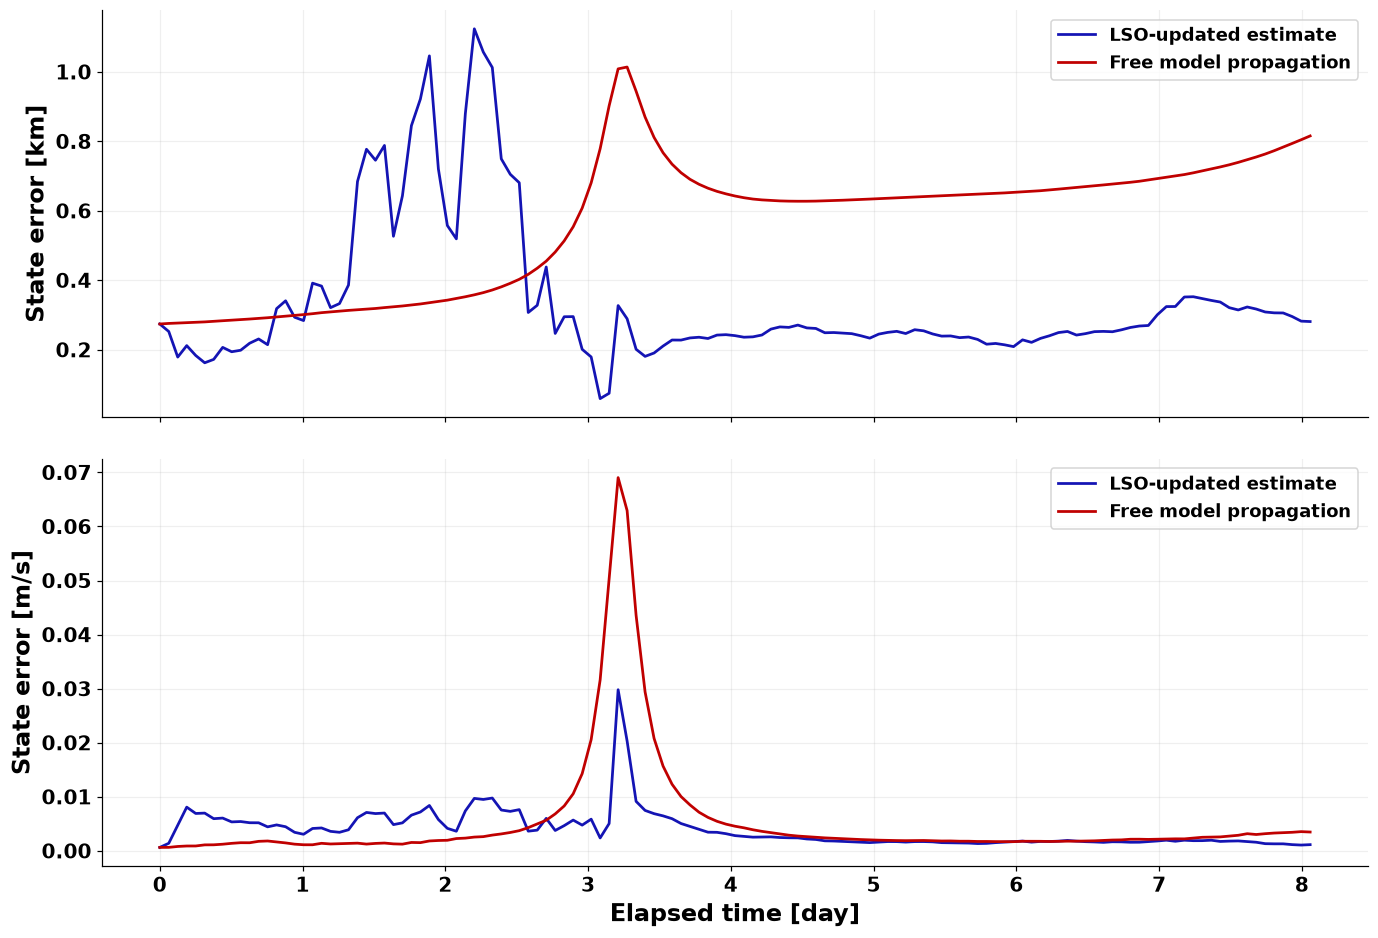

**Purpose:** Held-out truth is used only here to compare LSO-updated state estimates with free model propagation after its initial angular update.

**Result:** The LSO-updated 3-D RMSE is 0.395 km in position and 0.00527 m/s in velocity, quantifying navigation accuracy without treating estimated states as measurements.

In [2]:
scores={model:{split:sk.prediction_scores(orbit,rec,model_gains) for split,rec in data.items()}
        for model,model_gains in models.items()}
table(['Split','Model','Angular RMSE [arcsec]','Navigation position RMSE [km]','Navigation velocity RMSE [m/s]'],
      [(split,model,f"{q['angular_innovation_rmse_arcsec']:.3g}",
        f"{q['navigation']['position_rmse_km']:.3g}",f"{q['navigation']['velocity_rmse_m_s']:.3g}")
       for model,result in scores.items() for split,q in result.items() if split != 'training'])
(OUT/'prediction_scores.json').write_text(json.dumps(scores['Periodic gains'],indent=2)+'\n')
(OUT/'model_comparison_scores.json').write_text(json.dumps(scores,indent=2)+'\n')
test=data['test'];pred=sk.predict(orbit,test,gains);free=sk.predict(orbit,test,gains,free_run=True)
plots.validation(orbit,test,pred,free,OUT/'figures')
np.savez_compressed(OUT/'test_predictions.npz',**pred,free_simulation=free['navigation'])

## Do the residuals support the predictor?

Use standardized angular innovations with actual time lags and visibility gaps intact. Ljung–Box uses eligible contiguous runs with Holm adjustment. A mask-conditioned Monte Carlo maximum-CCF test covers the input/channel/lag family. No gaps or independent trajectories are concatenated, and no fitted ARMA degrees of freedom are subtracted for the fixed model on test data.

ADF/KPSS also uses contiguous observed runs, reporting insufficient support explicitly. Residual whiteness checks whether the assumed noise model is adequate. Residual–input correlation checks whether the commanded impulses remain related to the prediction error. Passing these checks does not guarantee that the orbit model or the station-keeping controller is accurate.

Out[3]: 75


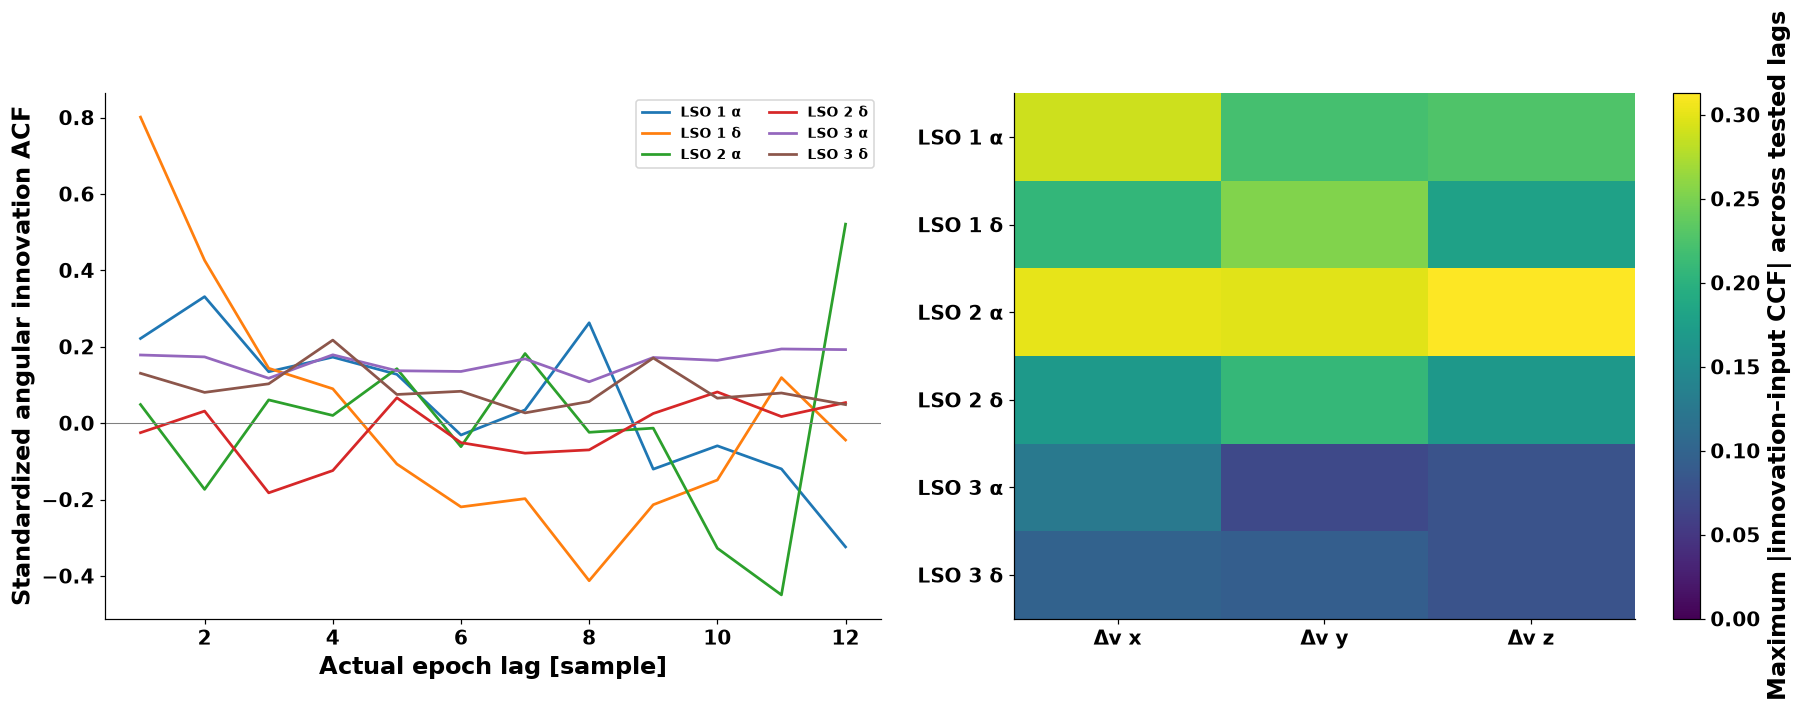

**Purpose:** The ACF and residual–input correlation screen the raw angular predictor while preserving visibility gaps and true time lags.

**Result:** Holm-adjusted Ljung–Box tests reject 2 of 8 eligible contiguous runs and the mask-conditioned global CCF p-value is 0.805, which assesses predictor/noise adequacy rather than controller success.

| Model | Ljung–Box rejects | Eligible runs | Input–innovation p |
| --- | --- | --- | --- |
| Global gains | 2 | 8 | 0.895 |
| Periodic gains | 2 | 8 | 0.805 |

| Angular channel | Contiguous samples | ADF p | KPSS p | Joint reading |
| --- | --- | --- | --- | --- |
| LSO 1 alpha | 14 | insufficient data | insufficient data | insufficient contiguous observations |
| LSO 1 delta | 14 | insufficient data | insufficient data | insufficient contiguous observations |
| LSO 2 alpha | 15 | insufficient data | insufficient data | insufficient contiguous observations |
| LSO 2 delta | 15 | insufficient data | insufficient data | insufficient contiguous observations |
| LSO 3 alpha | 71 | 0.983 | 0.01 | evidence against level stationarity |
| LSO 3 delta | 71 | 0.179 | 0.01 | evidence against level stationarity |

In [3]:
residual=ld.residual_report(pred['standardized'],test.u,orbit.settings['residual_lags'])
plots.residuals(residual,OUT/'figures')
global_pred=sk.predict(orbit,test,models['Global gains'])
global_residual=ld.residual_report(global_pred['standardized'],test.u,orbit.settings['residual_lags'])
table(['Model','Ljung–Box rejects','Eligible runs','Input–innovation p'],
      [(label,int(np.nansum(q['ljung_box_holm_p']<orbit.settings['alpha'])),
        q['eligible_whiteness_tests'],f"{q['ccf_global_p']:.3g}")
       for label,q in [('Global gains',global_residual),('Periodic gains',residual)]])
stationarity_rows=ld.stationarity_rows(pred['standardized'])
def fmt(p): return 'insufficient data' if p is None else f'{p:.3g}'
table(['Angular channel','Contiguous samples','ADF p','KPSS p','Joint reading'],[(r['channel'],r['contiguous_samples'],fmt(r['adf_p']),fmt(r['kpss_p']),r['reading']) for r in stationarity_rows])
(OUT/'innovation_stationarity.json').write_text(json.dumps(stationarity_rows,indent=2)+'\n')
np.savez_compressed(OUT/'residual_checks.npz',**{k:v for k,v in residual.items() if isinstance(v,np.ndarray)})
(OUT/'optical_residual_summary.json').write_text(json.dumps({k:v for k,v in residual.items() if not isinstance(v,np.ndarray)},indent=2)+'\n')

## Do LSO-guided station keeping limits hold over a year?

Guidance uses only the LSO-derived departure estimate, with state updates at every measurement sample and planner calls at every measurement sample (about 1.5 hours). Candidate burns are checked by nonlinear propagation. The one-year run reports sampled corridor performance and the cumulative commanded Δv from the actual simulated impulses.

The comparison holds the initial departure, noise seed and measurement cadence fixed. The updated controller starts planning corrections earlier, using a target of 30% of the corridor limits instead of the baselines’ 70%. The two baselines use the reference-linearized navigation filter. The extended filter propagates the estimated state with the nonlinear dynamics, recomputes its local STM and visible angle Jacobians, and accounts for uncertainty in executed impulse magnitude. It uses the same phase-dependent actuator fit and no truth-state updates. These are paired outcomes from one simulated year, with completion reported separately from corridor compliance.

findfont: Failed to find font weight bold for STIXSizeFiveSym, now using 400.
findfont: Failed to find font weight bold for cmmi10, now using 400.
findfont: Failed to find font weight bold for cmsy10, now using 400.
findfont: Failed to find font weight bold for cmr10, now using 400.
findfont: Failed to find font weight bold for cmtt10, now using 400.
findfont: Failed to find font weight bold for cmti10, now using 400.
findfont: Failed to find font weight bold for cmb10, now using 400.
findfont: Failed to find font weight bold for cmss10, now using 400.
findfont: Failed to find font weight bold for cmex10, now using 400.
findfont: Failed to find font weight bold for DejaVu Sans Display, now using 400.


| Model | Completed | First exit [day] | Annual commanded Δv [m/s] |
| --- | --- | --- | --- |
| Global gains | True | 19.145790906152698 | 5.732861087605663 |
| Periodic gains | True | 26.975656073280494 | 1.8220190019878808 |
| Periodic gains + extended navigation | True | None | 6.208615333787465 |

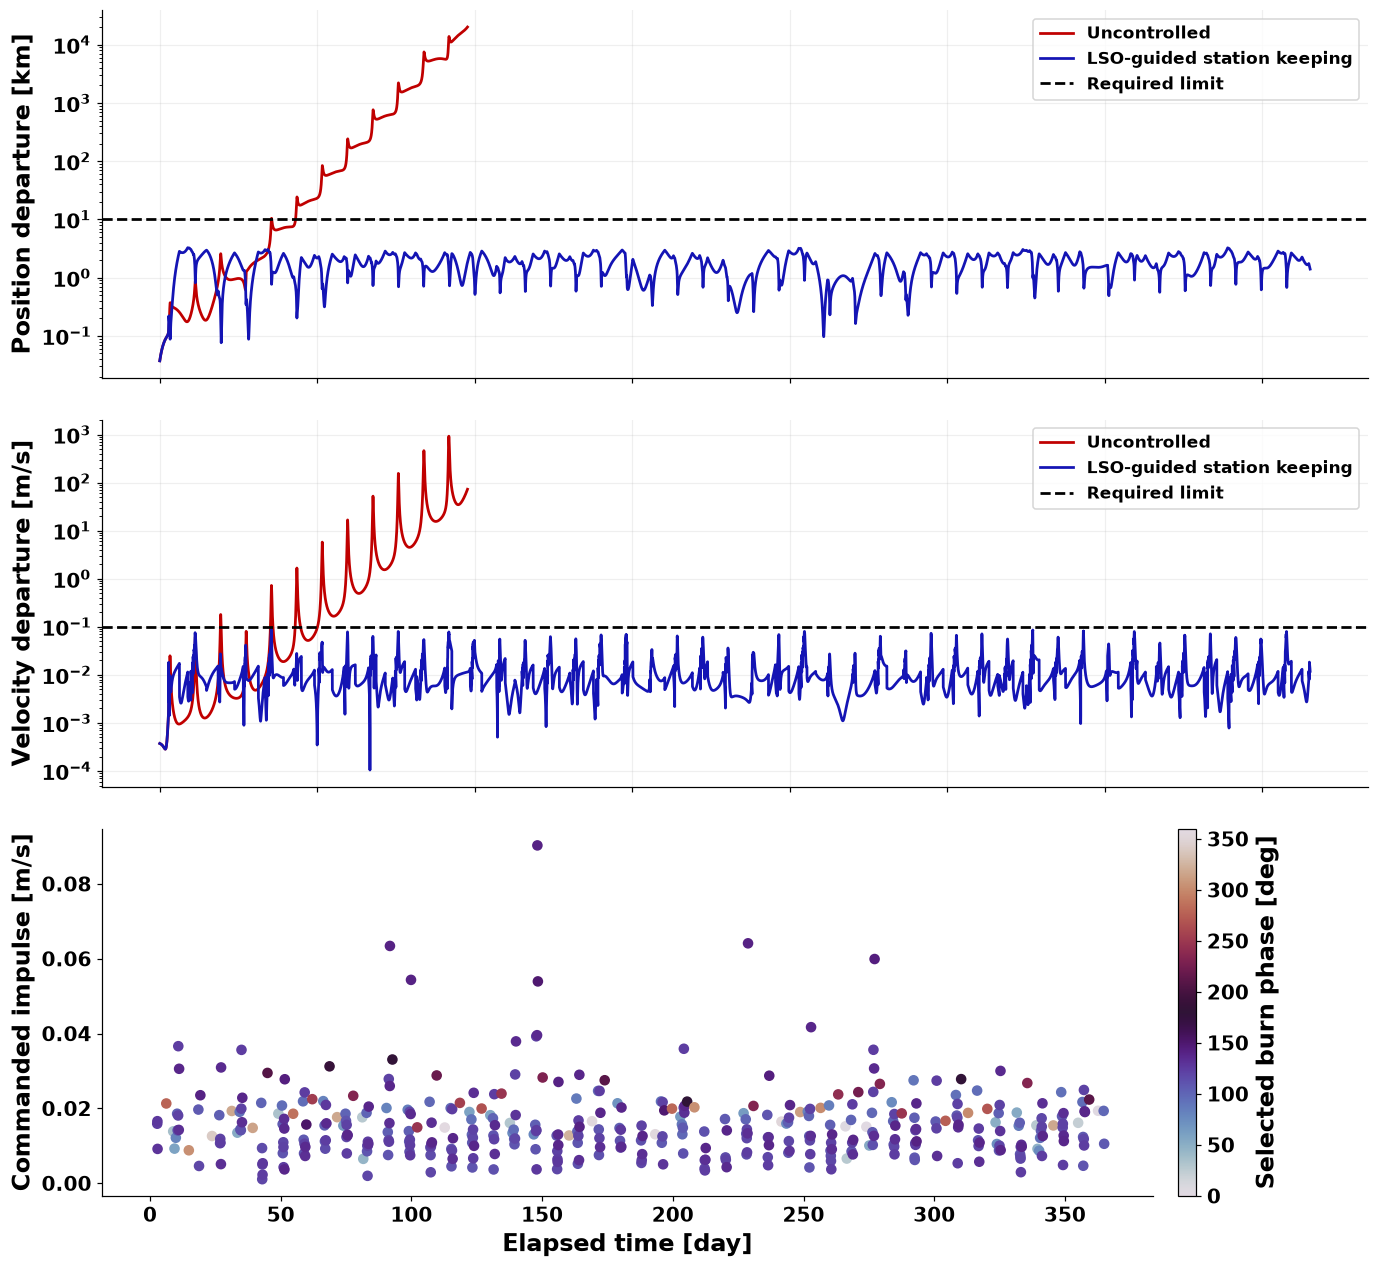

**Purpose:** True departure norms evaluate the LSO-guided controller, and coloured impulse markers show the magnitudes and orbital phases it selected.

**Result:** Peak position and velocity departures are 3.28 km and 0.0873 m/s, so both limits hold at all evaluated samples.

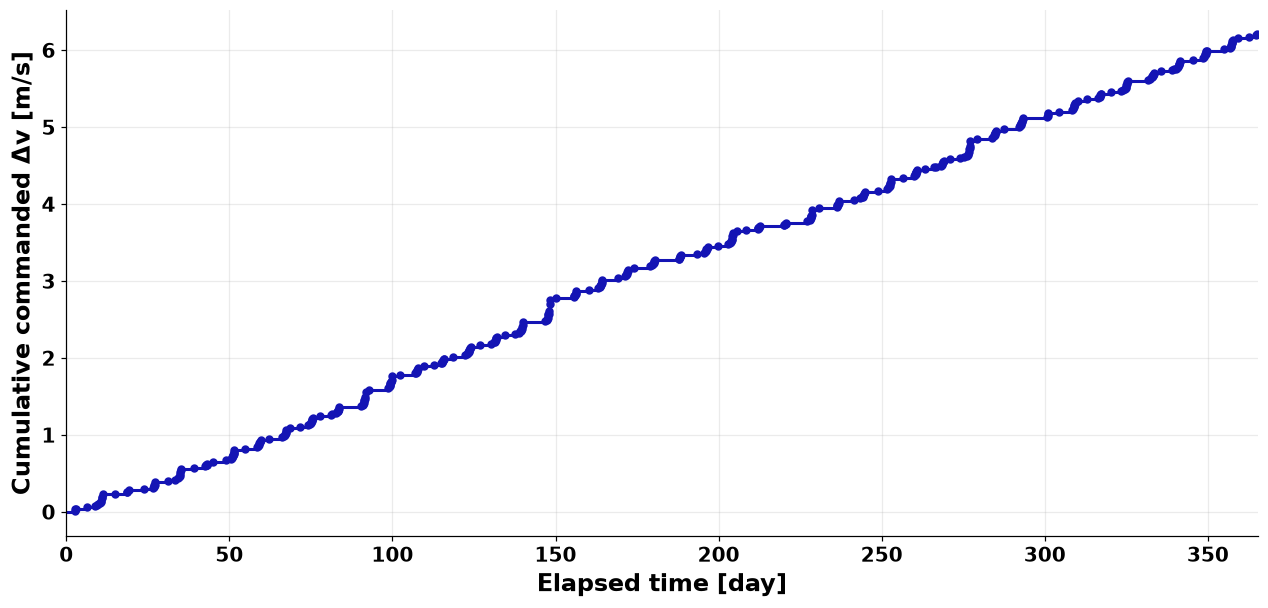

**Purpose:** The curve sums the magnitudes of commanded impulses over the simulated trajectory, so it reports accumulated Δv rather than a linearized yearly extrapolation.

**Result:** The completed requested horizon covers 365.25 days and accumulates 6.209 m/s of commanded Δv across 397 burns.

| Metric | Observed value |
| --- | --- |
| completed | True |
| requested_duration_days | 365.25 |
| last_day | 365.25 |
| planning_stride_steps | 1 |
| planning_margin | 0.3 |
| maximum_position_km | 3.2830101985900506 |
| maximum_velocity_m_s | 0.08728449469174378 |
| all_evaluated_samples_inside | True |
| first_sampled_exit_day | None |
| burns | 397 |
| total_commanded_delta_v_m_s | 6.208615333787465 |
| annual_delta_v_m_s | 6.208615333787465 |
| visible_epoch_fraction | 0.9962082040675629 |

**Noise-model conclusion:** 2/8 eligible whiteness tests reject after adjustment and the global residual–input p-value is 0.805, so these tests flag predictor/noise inadequacy.

**Station-keeping conclusion:** both required norms remain inside their limits at all evaluated samples of the completed run.

In [4]:
controllers={label:(g,'linear') for label,g in models.items()}
controllers['Periodic gains + extended navigation']=(gains,'extended')
trials={model:sk.stationkeeping_trial(
    orbit,model_gains, navigation=mode,
    duration_days=orbit.settings['annual_horizon_days'],
    planning_stride_steps=orbit.settings['annual_planning_stride_steps'],
    stop_on_departure_cutoff=False)
    for model,(model_gains,mode) in controllers.items()}
trial=trials['Periodic gains + extended navigation']
comparison={model:result['summary'] for model,result in trials.items()}
(OUT/'annual_model_comparison.json').write_text(json.dumps(comparison,indent=2)+'\n')
table(['Model','Completed','First exit [day]','Annual commanded Δv [m/s]'],
      [(model,q['completed'],q['first_sampled_exit_day'],q['annual_delta_v_m_s'])
       for model,q in comparison.items()])
if (OUT/'uncontrolled.npz').exists():
    with np.load(OUT/'uncontrolled.npz') as z: no_day,no_y=z['day'],z['output']
else: no_day,no_y,_=sk.uncontrolled(orbit)
plots.controlled(orbit,trial,no_day,no_y,OUT/'figures')
plots.annual_delta_v(trial,OUT/'figures')
summary=trial['summary']
table(['Metric','Observed value'],[(k,summary[k]) for k in ('completed','requested_duration_days','last_day','planning_stride_steps','planning_margin','maximum_position_km','maximum_velocity_m_s','all_evaluated_samples_inside','first_sampled_exit_day','burns','total_commanded_delta_v_m_s','annual_delta_v_m_s','visible_epoch_fraction')])
np.savez_compressed(OUT/'closed_loop.npz',**{k:v for k,v in trial.items() if k!='summary'})
(OUT/'closed_loop_summary.json').write_text(json.dumps(summary,indent=2)+'\n')
rejects=int(np.nansum(residual['ljung_box_holm_p']<.05))
display(Markdown(f'**Noise-model conclusion:** {rejects}/{residual["eligible_whiteness_tests"]} eligible whiteness tests reject after adjustment and the global residual–input p-value is {residual["ccf_global_p"]:.3g}, so these tests '+('flag predictor/noise inadequacy.' if rejects or residual['ccf_global_p']<.05 else 'do not reject the tested assumptions at 5%, without proving the model correct.')))
display(Markdown('**Station-keeping conclusion:** '+('both required norms remain inside their limits at all evaluated samples of the completed run.' if summary['completed'] and summary['all_evaluated_samples_inside'] else f'the extended-navigation controller does not establish the full corridor requirement, with observed peaks of {summary["maximum_position_km"]:.3g} km and {summary["maximum_velocity_m_s"]:.3g} m/s.')))

## How often does the single-burn controller stay inside the corridor?

The annual Monte Carlo benchmark ran the periodic STM and extended navigation filter for 20 trials of 365.25 days. It varied the initial position and velocity errors and lunar surface observer angle noise. Initial errors had per-axis standard deviations of 30 m and 0.3 mm/s, and angle noise had a standard deviation of 1 arcsecond. The starting orbital phase, simulated dynamics and actuator gains were fixed.

| Error magnitude | Corridor limit | Peak of pointwise mean | Worst individual peak |
| --- | ---: | ---: | ---: |
| Position | 10 km | 2.545 km | 4.231 km |
| Velocity | 0.100 m/s | 0.0682 m/s | 0.1383 m/s |

The mean stayed inside both limits at every sampled epoch. **9 of 20 trials (45%)** stayed inside both limits for the full year. The other 11 trials crossed the velocity limit, with the earliest observed exit on day 35.4. The average uses the magnitude of each trial’s error at each epoch. Mean compliance and full-year trial compliance answer different questions.

Across all completed trials, annual commanded Δv averaged 6.87 m/s (range 6.48–7.38 m/s), with an average of 426 burns.

[Benchmark run and downloadable trial data](https://github.com/scottblender/Halo_Orbit_Tracking/actions/runs/45171529580)

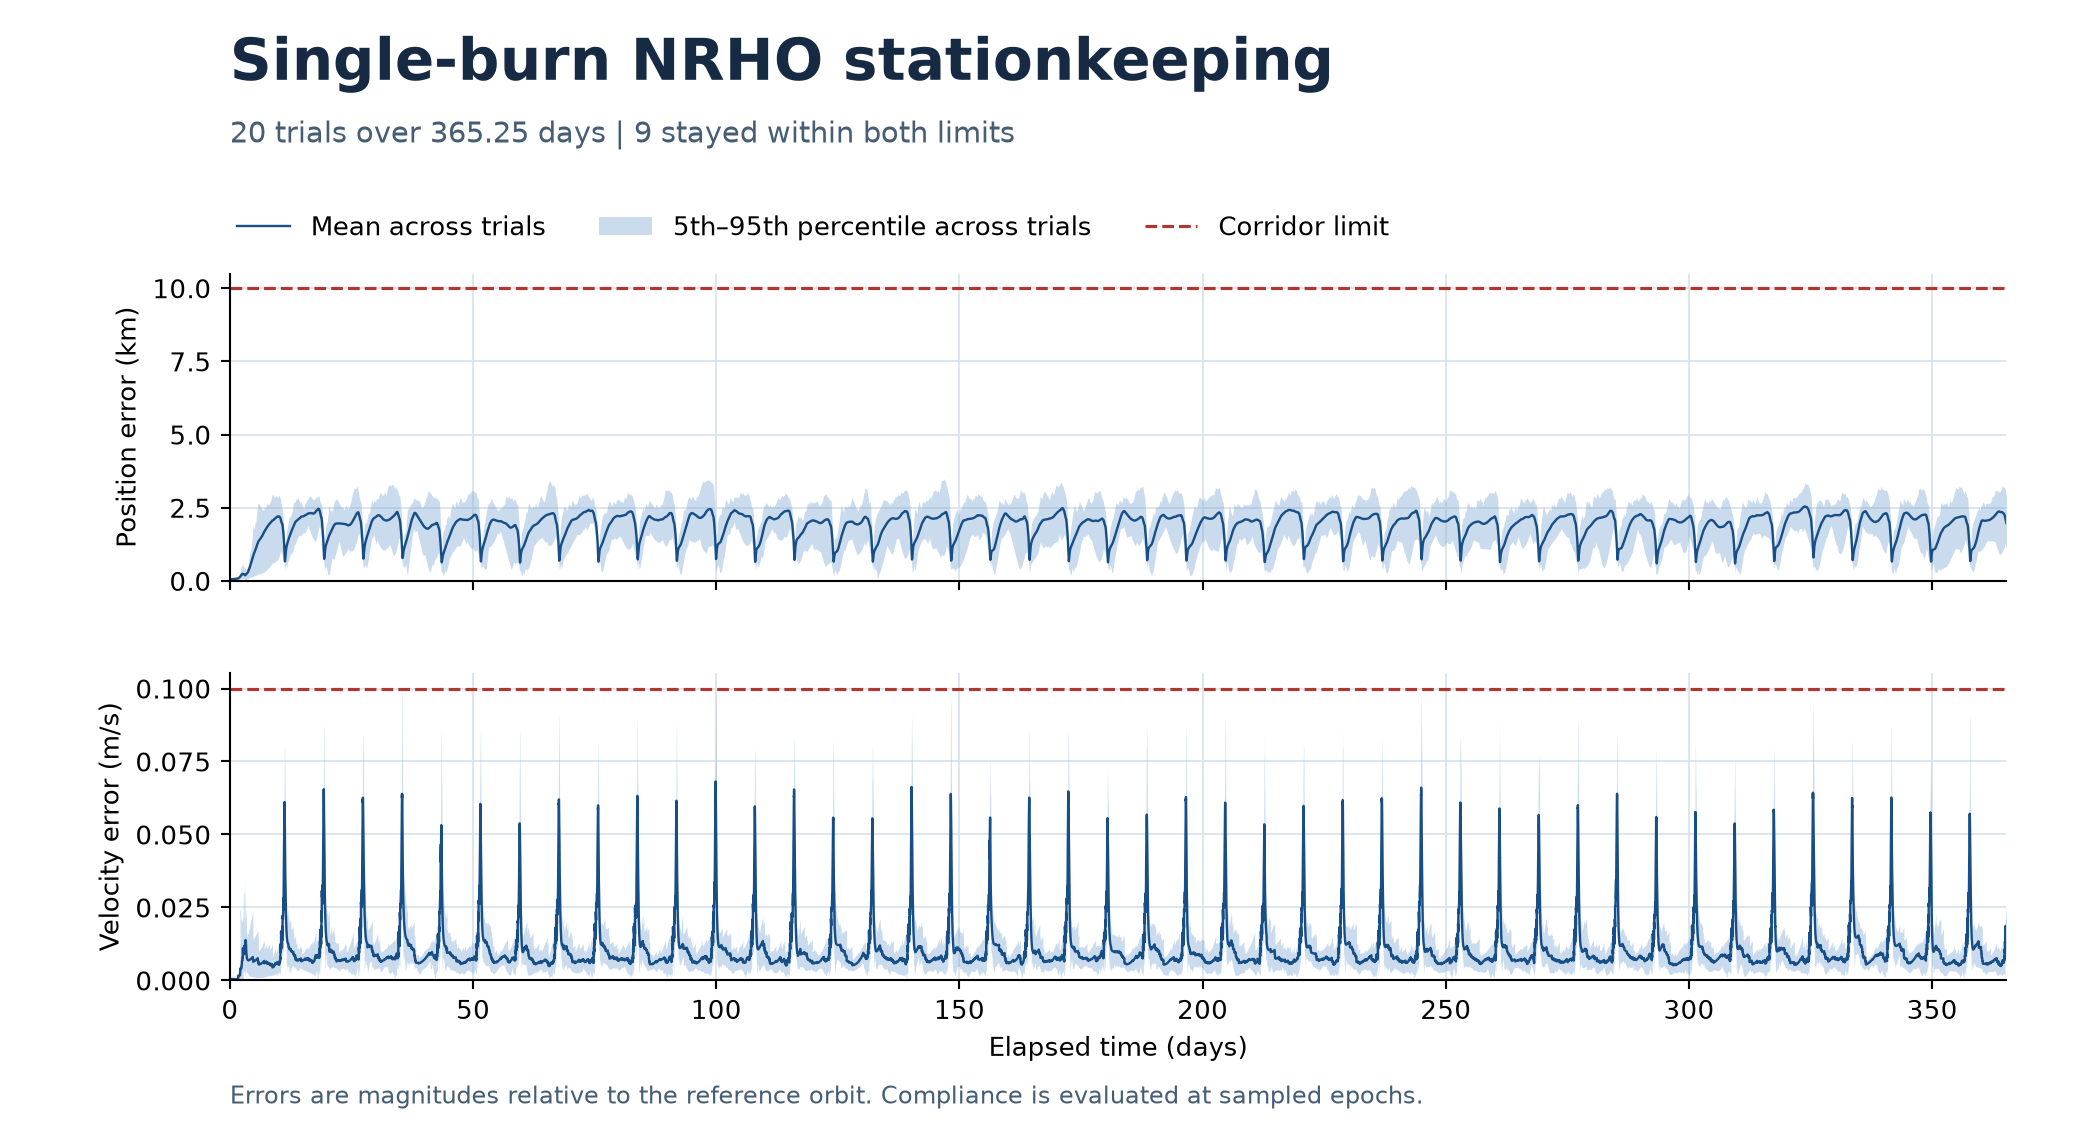

In [5]:
from IPython.display import Image
display(Image(filename=ROOT / 'docs/figures/stationkeeping_mc.png', width=1000, alt='Annual Monte Carlo position and velocity errors with corridor limits'))

## Next model discussion

Stationarity checks describe the records, while the phase-dependent impulse sensitivity motivates the periodic model structure. Held-out prediction, residual whiteness and annual corridor performance determine what the additional local gains are worth. Review LSO availability, gain uncertainty, raw angular residuals and navigation error before selecting a local OE/BJ model or periodic parameter basis (Studio 13). NARX remains deferred. Improving navigation or the burn planner may matter more than increasing black-box complexity.